# Zoom — Spectral Clustering — Breast Cancer Wisconsin (Diagnostic)

**Course:** UE 5BM753 — Supervised and Unsupervised Learning for Biology
**Part of:** the Breast Cancer Wisconsin (Diagnostic) final report, split into
per-step notebooks. See `README.md` for the overall narrative and conclusion.

**Question addressed here:** do the data naturally separate into two clusters that match the known diagnosis, without ever using the labels, and is there evidence of hidden sub-structure beyond those two groups?

Tunes and evaluates Spectral Clustering more closely, restricted to the features selected in `04_Feature_Selection.ipynb`.

Spectral Clustering was the strongest unsupervised baseline in the initial
screening, based on its match to the true diagnosis (ARI). This notebook tunes and
evaluates it more closely, in five steps:
- **Choosing the number of clusters**: silhouette score is swept over a range of
  cluster counts, since Spectral Clustering has no centroids and no elbow/inertia to
  rely on.
- **Fitting the final clustering**: the best cluster count is used to refit the
  model, and the result is compared to the true diagnosis using the same external
  metrics as the screening (ARI, homogeneity, completeness, V-measure).
- **Checking for sub-structure within each class**: malignant and benign samples are
  clustered separately, to check whether the cases the model misclassifies form a
  real sub-type rather than scattered noise.
- **Comparison: all features vs. selected features**: the resulting match to the
  diagnosis is compared to the screening's result on all 30 features, to check
  whether the feature reduction helps or hurts the natural clustering structure.
- **Comparing affinities**: the k-NN affinity used above is compared to an RBF
  kernel, to check whether picking the affinity by silhouette alone, not just the
  number of clusters, could also be misleading.

## Setup

Defines the paths used below and loads the data and the features selected
earlier.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

sys.path.append(os.path.join("..", "01_scripts"))
from dataset import load_data, get_feature_columns
from cluster_selection import run_spectral_range
from plots import plot_silhouette_by_k

# This notebook only needs the files exported by earlier notebooks, not their
# in-memory variables, so it can run entirely on its own.
RANDOM_STATE = 42
DATA_PATH = os.path.join("..", "02_data", "raw", "10_Breast_Cancer_Wisconsin_Diagnostic.csv")
RESULTS_DIR = os.path.join("..", "04_results")
FIGURES_DIR = os.path.join("..", "05_figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

df = load_data(DATA_PATH)
features = get_feature_columns(df)

# Feature names only, not the train/test CSVs: those cover only part of the
# samples and use a train-only scaler. Clustering uses all 569 samples instead.
selected_features = pd.read_csv(os.path.join(RESULTS_DIR, "04_selected_features.csv"))["feature"].tolist()

X_scaled_selected = StandardScaler().fit_transform(df[selected_features].values)

### Choosing the number of clusters

Spectral Clustering has no centroids, so there is no elbow/inertia to rely on for
picking the number of clusters. Silhouette score is swept over a range instead,
using the features selected earlier.

In [ ]:
# Sweep n_clusters, pick the best by silhouette (no true labels used here).
spectral_k_results = run_spectral_range(X_scaled_selected, k_range=range(2, 8), random_state=RANDOM_STATE)
spectral_k_results.to_csv(os.path.join(RESULTS_DIR, "06_spectral_k_selection.csv"), index=False)

plot_silhouette_by_k(
    spectral_k_results,
    os.path.join(FIGURES_DIR, "06_spectral_k_selection.png"),
    title="Spectral Clustering: silhouette by number of clusters (selected features)",
)

best_k = int(spectral_k_results.loc[spectral_k_results["silhouette"].idxmax(), "k"])
print(f"Optimal n_clusters by silhouette: {best_k}")
display(spectral_k_results.round(4))

**Findings.** Silhouette peaks at k = 2 (0.399), well above every other value
tested (0.16 to 0.19 for k = 3 to 7). The clustering naturally recovers 2 groups on
the selected features alone, without ever using the diagnosis, matching the known
two-class structure of the data.

### Fitting the final clustering

The cluster count that reached the best silhouette score above is used to refit
Spectral Clustering, using the k-NN affinity (validated further below against RBF).
Its match to the true diagnosis is measured with the same
metrics as the initial screening (ARI, homogeneity, completeness, V-measure), even
though the diagnosis is never used to fit the clustering itself. A PCA is
recomputed on the same selected features, only to place each point on a 2D graph.
It has no role in the clustering itself.

In [ ]:
from sklearn.cluster import SpectralClustering
from evaluation import evaluate_clusterers

# Refit with the chosen k, then score against the true diagnosis (external validation only).
spectral_final = SpectralClustering(n_clusters=best_k, affinity="nearest_neighbors", random_state=RANDOM_STATE)

spectral_eval = evaluate_clusterers(
    {"Spectral (selected features)": spectral_final}, X_scaled_selected, df["label"].values
)
spectral_eval.to_csv(os.path.join(RESULTS_DIR, "06_spectral_final_metrics.csv"), index=False)

print(f"--- Spectral Clustering (n_clusters={best_k}, selected features) vs. true diagnosis ---")
display(spectral_eval.round(4))

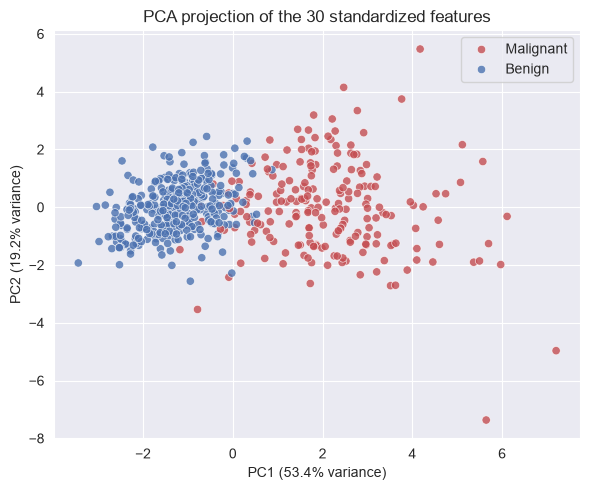

In [4]:
from plots import plot_pca_projection

# PCA recomputed on the selected features only: gives the 2D coordinates for the
# plot below, but plays no role in the clustering itself.
pca_selected, X_pca_selected = plot_pca_projection(
    X_scaled_selected, df["label"].values,
    os.path.join(FIGURES_DIR, "06_pca_projection_selected_features.png"),
    random_state=RANDOM_STATE,
)

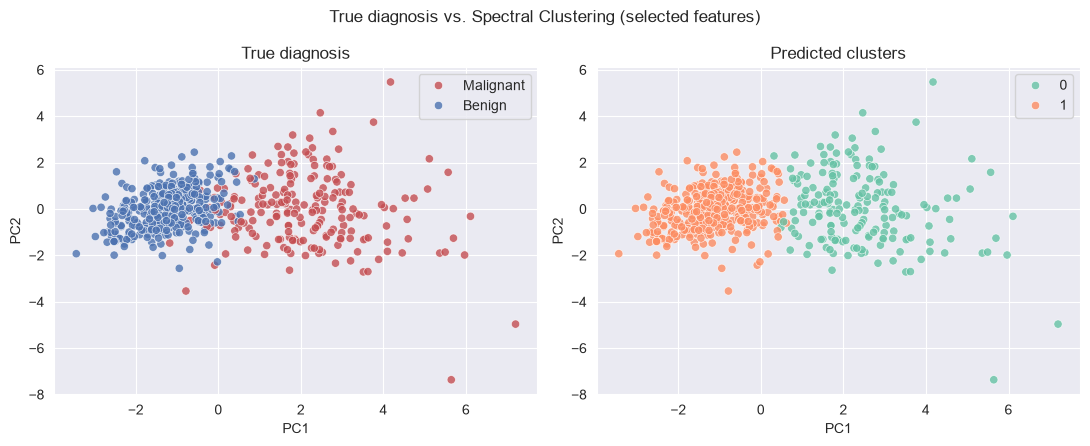

In [5]:
from plots import plot_cluster_vs_diagnosis

# Re-fit to get the cluster labels for the comparison figure below --
# evaluate_clusterers only returns summary metrics, not the labels themselves.
spectral_labels = spectral_final.fit_predict(X_scaled_selected)
plot_cluster_vs_diagnosis(
    X_pca_selected, df["label"].values, spectral_labels,
    os.path.join(FIGURES_DIR, "06_spectral_vs_diagnosis_selected.png"),
    title="True diagnosis vs. Spectral Clustering (selected features)"
)

In [ ]:
# Confusion-matrix-style breakdown: how many samples land in the "wrong" cluster relative to diagnosis.
cluster_to_class = {}
for c in np.unique(spectral_labels):
    vals, counts = np.unique(df["label"].values[spectral_labels == c], return_counts=True)
    cluster_to_class[c] = vals[np.argmax(counts)]
pred_class = np.array([cluster_to_class[c] for c in spectral_labels])

confusion = pd.crosstab(
    pd.Series(df["label"].values, name="True diagnosis").map({0: "Benign", 1: "Malignant"}),
    pd.Series(pred_class, name="Predicted cluster").map({0: "Benign", 1: "Malignant"})
)
print("--- Spectral Clustering vs. true diagnosis (confusion-matrix style) ---")
display(confusion)

**Findings.** Refit with 2 clusters, Spectral Clustering reaches an ARI of 0.792
against the true diagnosis, with similar homogeneity (0.697) and completeness
(0.730). This confirms the natural groups found on the 7 selected features largely
coincide with benign vs. malignant, even though the clustering never saw the
labels.

### Checking for sub-structure within each class

The clustering above assumes each diagnosis class is internally homogeneous, but the 29 malignant
cases it misclassifies (confusion matrix above) could instead reflect a real sub-type rather than
noise. This is checked here by clustering malignant and benign samples **separately**, each on their
own: isolating a class removes the dominant benign-vs-malignant signal, which could otherwise mask a
weaker, within-class grouping.

In [ ]:
from sklearn.metrics import silhouette_score


# If a class were internally homogeneous, clustering it alone should show no real
# structure. Isolating each class removes the dominant benign/malignant signal that
# would otherwise overshadow a weaker, within-class sub-type, if one exists.
def sweep_within_class(X_class, k_range=range(2, 6)):
    rows = []
    for k in k_range:
        labels = SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                     random_state=RANDOM_STATE).fit_predict(X_class)
        rows.append({"k": k, "silhouette": silhouette_score(X_class, labels)})
    return pd.DataFrame(rows)


malignant_k_results = sweep_within_class(X_scaled_selected[df["label"].values == 1])
benign_k_results = sweep_within_class(X_scaled_selected[df["label"].values == 0])

within_class_results = pd.concat([
    malignant_k_results.assign(subset="Malignant-only"),
    benign_k_results.assign(subset="Benign-only"),
], ignore_index=True)
within_class_results.to_csv(os.path.join(RESULTS_DIR, "06_within_class_k_selection.csv"), index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(malignant_k_results["k"], malignant_k_results["silhouette"], marker="o",
        label="Malignant-only", color="#C44E52")
ax.plot(benign_k_results["k"], benign_k_results["silhouette"], marker="o",
        label="Benign-only", color="#4C72B0")
ax.axhline(0.25, color="gray", linestyle="--", linewidth=1,
           label="Kaufman & Rousseeuw (1990) threshold for 'no substantial structure'")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title("Silhouette by k, clustering each diagnosis class on its own")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "06_within_class_k_selection.png"), dpi=150)
plt.show()

best_mal_k = int(malignant_k_results.loc[malignant_k_results["silhouette"].idxmax(), "k"])
best_ben_k = int(benign_k_results.loc[benign_k_results["silhouette"].idxmax(), "k"])
print(f"Malignant-only: best k={best_mal_k}, silhouette={malignant_k_results['silhouette'].max():.4f}")
print(f"Benign-only: best k={best_ben_k}, silhouette={benign_k_results['silhouette'].max():.4f}")

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns


# Refit each class at its own best k, then visualize the actual partition on a 2D PCA
# recomputed within that class only -- for visualization; plays no role in the clustering.
def plot_within_class_partition(ax, X_class, k, title):
    labels = SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                 random_state=RANDOM_STATE).fit_predict(X_class)
    X_pca_class = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_class)
    sns.scatterplot(x=X_pca_class[:, 0], y=X_pca_class[:, 1], hue=labels.astype(str),
                     palette="Set2", alpha=0.75, ax=ax, legend=False)
    ax.set_title(title)
    ax.set_xlabel("PC1 (within-class)")
    ax.set_ylabel("PC2 (within-class)")
    return labels


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_within_class_partition(axes[0], X_scaled_selected[df["label"].values == 1], best_mal_k,
                             f"Malignant-only, k={best_mal_k}")
plot_within_class_partition(axes[1], X_scaled_selected[df["label"].values == 0], best_ben_k,
                             f"Benign-only, k={best_ben_k}")
fig.suptitle("Best-silhouette partition within each class")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "06_within_class_partition.png"), dpi=150)
plt.show()

**Findings.** Both malignant-only and benign-only clustering pick k = 2 as their best split by
silhouette, but the scores are modest: 0.207 and 0.205 respectively. Both fall below 0.25, the
threshold below which Kaufman & Rousseeuw (1990) consider a partition to show no substantial
structure. The PCA visualization above places each best-k partition on a 2D projection, to check this
visually alongside the numbers.

### Comparison: all features vs. selected features (k-NN affinity)

Spectral Clustering was already evaluated on all 30 features during the initial
screening. Comparing that result to the one obtained here, on the reduced feature
set, shows whether removing redundant and uninformative features helps or hurts how
well the natural clusters match the true diagnosis.

In [ ]:
# All-30-features result: already computed in the initial screening.
screening_eval = pd.read_csv(os.path.join(RESULTS_DIR, "03_clustering_eval.csv"))
spectral_all_features = screening_eval[screening_eval["model"] == "Spectral"].iloc[0]

comparison = pd.DataFrame([
    {"features": "All 30 features", "n_features": len(features),
     "ARI_vs_diagnosis": spectral_all_features["ARI_vs_diagnosis"],
     "silhouette": spectral_all_features["silhouette"]},
    {"features": "Selected features", "n_features": len(selected_features),
     "ARI_vs_diagnosis": spectral_eval["ARI_vs_diagnosis"].iloc[0],
     "silhouette": spectral_eval["silhouette"].iloc[0]},
])
comparison.to_csv(os.path.join(RESULTS_DIR, "06_spectral_feature_comparison.csv"), index=False)

print("--- Spectral Clustering: all features vs. selected features ---")
display(comparison.round(4))

from plots import plot_ari_comparison_bar

plot_ari_comparison_bar(
    comparison, "features", "ARI_vs_diagnosis",
    colors=["#8c8c8c", "#C44E52"],
    title="Spectral Clustering: feature reduction effect on ARI",
    out_path=os.path.join(FIGURES_DIR, "06_spectral_feature_comparison.png"),
)

**Findings.** Restricting to the 7 selected features improves both scores compared
to all 30 features: ARI rises from 0.761 to 0.792, and silhouette from 0.337 to
0.399. Removing redundant and less informative features does not only help the
supervised model; it also makes the natural clustering structure clearer.

### Separation Topologies: k-NN vs. RBF
 
Spectral Clustering's affinity function defines the notion of "similarity" the algorithm partitions on, and different topologies can converge on very different partitions of the same data. 
Two families are compared here on the 7 selected features: 
- a k-Nearest Neighbors graph (discrete, local) 
- and an RBF kernel (continuous, similarity via exponential decay).
 
For a controlled comparison, both families use the same cluster count (`n_clusters=2`) and the same label-assignment step (`assign_labels='kmeans'`, matching the baseline model above), varying only the affinity and its hyperparameter (`n_neighbors` for k-NN, `gamma` for RBF). As with the cluster-count selection above, the hyperparameter within each family is chosen by silhouette alone, without using the diagnosis; ARI against the true diagnosis is computed afterward, for external validation only.

In [ ]:
from sklearn.metrics import silhouette_score, adjusted_rand_score
from plots import plot_topology_sweep
 
ASSIGN_LABELS = "kmeans"
y_true = df["label"].values
 
n_neighbors_range = [5, 8, 10, 15, 20, 30]
gamma_range = np.logspace(-3, 0, 8)
 
 
# For each hyperparameter value: fit, then record silhouette (label-free) and ARI (uses true labels, for comparison only).
def sweep_spectral(param_name, param_values, **fixed_kwargs):
    rows = []
    for value in param_values:
        model = SpectralClustering(
            n_clusters=2, assign_labels=ASSIGN_LABELS, random_state=RANDOM_STATE,
            **{param_name: value}, **fixed_kwargs
        )
        labels = model.fit_predict(X_scaled_selected)
        rows.append({
            param_name: value,
            "silhouette": silhouette_score(X_scaled_selected, labels),
            "ARI_vs_diagnosis": adjusted_rand_score(y_true, labels),
        })
    return pd.DataFrame(rows)
 
 
knn_results = sweep_spectral("n_neighbors", n_neighbors_range, affinity="nearest_neighbors")
rbf_results = sweep_spectral("gamma", gamma_range, affinity="rbf")
 
topology_sweep_results = pd.concat(
    [knn_results.assign(topology="k-NN"), rbf_results.assign(topology="RBF")], ignore_index=True
)
topology_sweep_results.to_csv(os.path.join(RESULTS_DIR, "06_spectral_topology_sweep.csv"), index=False)
 
plot_topology_sweep(knn_results, rbf_results, os.path.join(FIGURES_DIR, "06_spectral_topology_sweep.png"))
 
# Pick each family's own silhouette-optimal setting, to compare below.
best_knn = knn_results.loc[knn_results["silhouette"].idxmax()]
best_rbf = rbf_results.loc[rbf_results["silhouette"].idxmax()]
 
print(f"Best k-NN by silhouette: n_neighbors={int(best_knn['n_neighbors'])}, "
      f"silhouette={best_knn['silhouette']:.4f}, ARI={best_knn['ARI_vs_diagnosis']:.4f}")
print(f"Best RBF by silhouette: gamma={best_rbf['gamma']:.4f}, "
      f"silhouette={best_rbf['silhouette']:.4f}, ARI={best_rbf['ARI_vs_diagnosis']:.4f}")

**Findings.** Silhouette and ARI diverge sharply within the RBF family: silhouette rises monotonically
with `gamma` (from 0.40 at gamma=0.001 to 0.66 at gamma≈0.14), while ARI collapses from 0.79 to 0.005
over the same range, the two curves crossing between gamma≈0.05 and gamma≈0.14. The silhouette-optimal
RBF configuration (gamma=0.1389, silhouette=0.6629) is therefore the single worst point of the sweep
for clinical alignment (ARI=0.0048) — essentially a random partition. The k-NN family shows no such
divergence: silhouette stays flat and low (~0.40) across the full range of `n_neighbors`, while ARI
stays high and stable (0.78–0.80), so its silhouette-optimal configuration (n_neighbors=10,
silhouette=0.3990, ARI=0.7920) is also a strong match to the diagnosis. This confirms the risk stated
above is not hypothetical: on this dataset, selecting the RBF affinity purely by silhouette would have
picked the geometrically tightest but clinically meaningless partition, while the k-NN affinity remains
robust to the same selection rule.

In [ ]:
from plots import plot_topology_comparison

# Refit each family's silhouette-optimal setting, to visualize side by side.
final_models = {
    f"Spectral (k-NN, n_neighbors={int(best_knn['n_neighbors'])})": SpectralClustering(
        n_clusters=2, affinity="nearest_neighbors", n_neighbors=int(best_knn["n_neighbors"]),
        assign_labels=ASSIGN_LABELS, random_state=RANDOM_STATE
    ),
    f"Spectral (RBF, gamma={best_rbf['gamma']:.4f})": SpectralClustering(
        n_clusters=2, affinity="rbf", gamma=best_rbf["gamma"],
        assign_labels=ASSIGN_LABELS, random_state=RANDOM_STATE
    ),
}

plot_topology_comparison(
    final_models, X_scaled_selected, X_pca_selected, y_true,
    os.path.join(FIGURES_DIR, "06_spectral_topology_comparison.png"),
)

**Findings.** The silhouette-optimal RBF configuration reaches the highest silhouette of the comparison
(0.663) but an ARI of 0.005, while k-NN (silhouette=0.399) reaches an ARI of 0.792. Higher silhouette
does not translate into better diagnostic alignment here.

### Comparison: feature selection and affinity choice together

The two comparisons above can be combined into one: how does ARI change across
three configurations, all 30 features, the 7 selected features with the k-NN
affinity, and the 7 selected features with the silhouette-optimal RBF affinity?

In [ ]:
# Combine the two comparisons above into one 3-way ARI comparison.
comparison_full = pd.DataFrame([
    {"configuration": "All 30 features", "ARI_vs_diagnosis": spectral_all_features["ARI_vs_diagnosis"]},
    {"configuration": "Selected features (k-NN)", "ARI_vs_diagnosis": spectral_eval["ARI_vs_diagnosis"].iloc[0]},
    {"configuration": "Selected features (RBF)", "ARI_vs_diagnosis": best_rbf["ARI_vs_diagnosis"]},
])
comparison_full.to_csv(os.path.join(RESULTS_DIR, "06_spectral_full_comparison.csv"), index=False)

print("--- Spectral Clustering: ARI by feature set and affinity ---")
display(comparison_full.round(4))

plot_ari_comparison_bar(
    comparison_full, "configuration", "ARI_vs_diagnosis",
    colors=["#8c8c8c", "#4C72B0", "#C44E52"],
    title="Spectral Clustering: ARI by feature set and affinity",
    out_path=os.path.join(FIGURES_DIR, "06_spectral_full_comparison.png"),
    figsize=(7, 4),
)

**Findings.** Feature selection and affinity choice both matter, but not equally.
Restricting to 7 features raises ARI from 0.761 to 0.792 with the k-NN affinity, a
modest gain. Switching the silhouette-optimal affinity from k-NN to RBF collapses
ARI to 0.005, a much larger loss. On this dataset, the affinity choice dominates
over the feature selection gain.

## Discussion
 
Spectral Clustering was chosen for this detailed analysis because it achieved the highest ARI against
the true diagnosis during initial screening, avoiding the single-cluster collapse observed with
Agglomerative clustering. Restricting the dataset to the 7 features selected via L1 regularization
simultaneously improved the clinical alignment (ARI increased from 0.761 to 0.792) and the geometric
separation (Silhouette increased from 0.337 to 0.399).
 
The topology comparison (`06_spectral_topology_sweep.csv`, figures above) illustrates a general risk of
purely mathematical optimization in biomedical contexts: silhouette and ARI are not guaranteed to peak
at the same hyperparameter. This is exactly what happens for RBF: its silhouette-optimal `gamma`
reaches the highest silhouette of the sweep (0.663) but the lowest ARI (0.005). Selecting a
configuration by silhouette alone does not guarantee that the resulting partition matches the clinical
outcome; an algorithm can converge on a secondary or technical source of variation that happens to be
easy to separate geometrically rather than on the diagnosis itself. The topology retained for the final
comparison above is k-NN, whose silhouette and ARI stay stable and clinically aligned across the full
`n_neighbors` range tested, unlike RBF.

**Limitations.** The clustering correctly groups 355/357 benign cases (99.4%) and 183/212 malignant
cases (86.3%). Clustering each class separately (above) finds no distinct sub-type behind the
misclassified cases in either class — silhouette stays modest (0.207 for malignant-only, 0.205 for
benign-only), below the 0.25 threshold below which Kaufman & Rousseeuw (1990) consider a partition to
show no substantial structure. The 29 misclassified malignant cases therefore appear to be individually
borderline rather than a coherent hidden group, though we did not investigate further what makes them
borderline.
 